# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

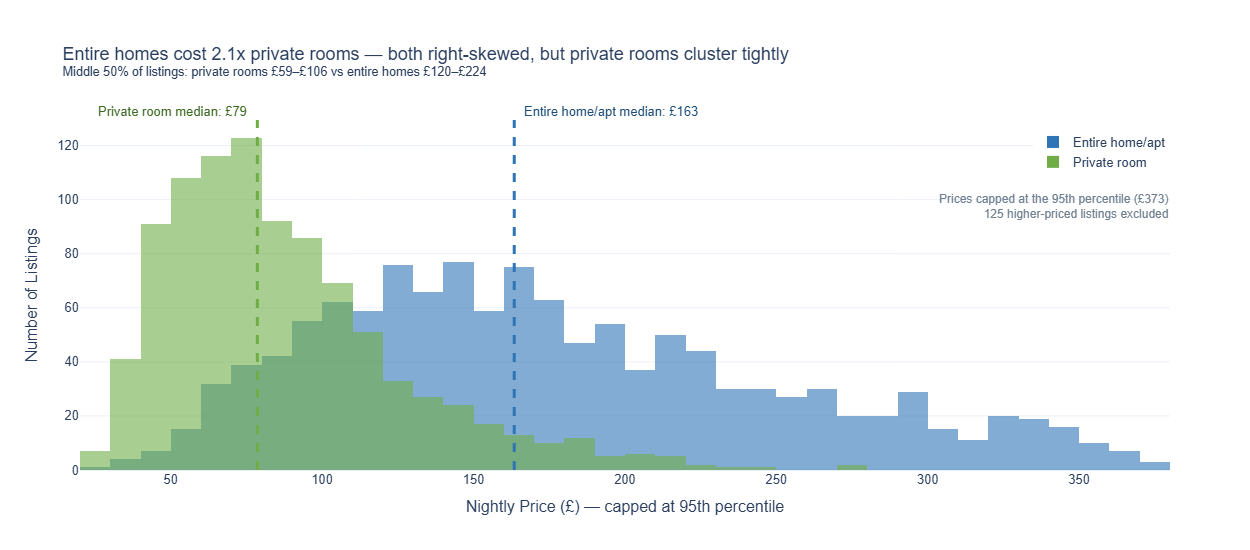

In [3]:
# Task 1
# YOUR CODE HERE

ROOM_COLOURS = {'Entire home/apt': '#2E75B6', 'Private room': '#70AD47'}
TEXT_COLOURS = {'Entire home/apt': '#1F4E79', 'Private room': '#3D6B24'}

df_t1 = df_cap[df_cap['room_type'].isin(ROOM_COLOURS.keys())].copy()

stats = df_t1.groupby('room_type')['price'].quantile([0.25, 0.5, 0.75]).unstack()
med_home, med_room = stats.loc['Entire home/apt', 0.5], stats.loc['Private room', 0.5]
n_excluded = (df['price'] > p95).sum()

fig = px.histogram(
    data_frame=df_t1,
    x='price',
    color='room_type',
    barmode='overlay',
    opacity=0.6,
    color_discrete_map=ROOM_COLOURS,
    category_orders={'room_type': list(ROOM_COLOURS.keys())},
    labels={'price': 'Nightly Price (£)', 'room_type': 'Room type'},
    height=550, width=1000,
    template='plotly_white'
)

fig.update_traces(xbins=dict(start=0, end=np.ceil(p95 / 10) * 10, size=10))

for room, med, side in [('Private room', med_room, 'left'), ('Entire home/apt', med_home, 'right')]:
    fig.add_vline(x=med, line_dash='dash', line_color=ROOM_COLOURS[room], line_width=3,
                  annotation=dict(
                      text=f'{room} median: £{med:.0f}',
                      font=dict(color=TEXT_COLOURS[room], size=13),
                      xanchor='right' if side == 'left' else 'left',
                      y=1, yanchor='bottom',      # label sits just above the plot area, clear of the bars
                      xshift=-8 if side == 'left' else 8,
                  ))

# Disclose the outlier cap
fig.add_annotation(
    x=1, y=0.8, xref='paper', yref='paper', xanchor='right', showarrow=False, align='right',
    text=f'Prices capped at the 95th percentile (£{p95:.0f})<br>{n_excluded} higher-priced listings excluded',
    font=dict(color='slategrey', size=12)
)

fig.update_layout(
    title=(f'Entire homes cost {med_home / med_room:.1f}x private rooms — both right-skewed, but private rooms cluster tightly'
           f'<br><sup>Middle 50% of listings: private rooms £{stats.loc["Private room", 0.25]:.0f}–£{stats.loc["Private room", 0.75]:.0f} '
           f'vs entire homes £{stats.loc["Entire home/apt", 0.25]:.0f}–£{stats.loc["Entire home/apt", 0.75]:.0f}</sup>'),
    font=dict(family='Arial', size=13),
    yaxis=dict(title='Number of Listings'),
    xaxis=dict(showgrid=False, title='Nightly Price (£) — capped at 95th percentile'),
    legend=dict(title='', x=1, y=0.98, xanchor='right', yanchor='top'),
    margin=dict(t=120),
)
fig.show()

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

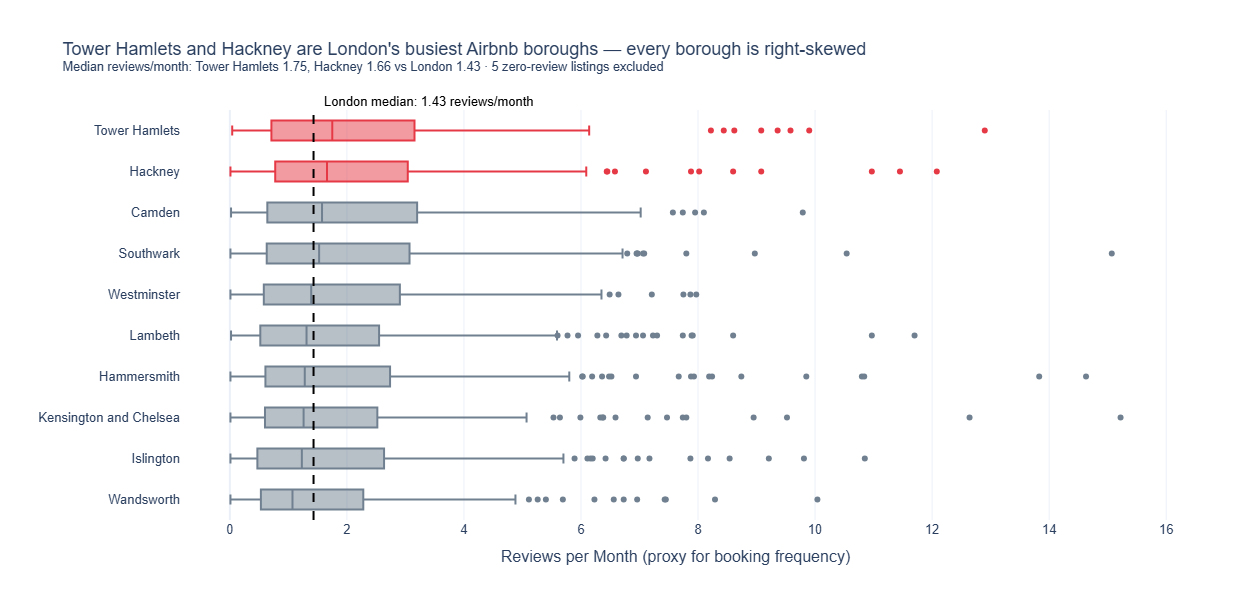

In [4]:
# Task 2
# YOUR CODE HERE

df_active = df[df['reviews_per_month'] > 0].copy()
n_zero = len(df) - len(df_active)

borough_median = (df_active.groupby('neighbourhood')['reviews_per_month']
                  .median().sort_values(ascending=False))
order = borough_median.index.tolist()
top2 = order[:2]
london_median = df_active['reviews_per_month'].median()

HIGHLIGHT, MUTED = '#E63946', 'slategrey'
colour_map = {b: HIGHLIGHT if b in top2 else MUTED for b in order}

fig = px.box(
    data_frame=df_active,
    x='reviews_per_month',
    y='neighbourhood',
    color='neighbourhood',
    orientation='h',                    # horizontal: long borough names stay readable
    color_discrete_map=colour_map,
    category_orders={'neighbourhood': order},
    points='outliers',                  # outliers as individual points
    labels={'reviews_per_month': 'Reviews per Month', 'neighbourhood': ''},
    height=600, width=1000,
    template='plotly_white'
)

fig.add_vline(x=london_median, line_dash='dash', line_color='black', line_width=2,
              annotation=dict(
                  text=f'London median: {london_median:.2f} reviews/month',
                  font=dict(color='black', size=13),
                  xanchor='left', yanchor='bottom', xshift=8, y=1,
              ))

fig.update_layout(
    title=(f'{top2[0]} and {top2[1]} are London\'s busiest Airbnb boroughs — every borough is right-skewed'
           f'<br><sup>Median reviews/month: {top2[0]} {borough_median[top2[0]]:.2f}, {top2[1]} {borough_median[top2[1]]:.2f} '
           f'vs London {london_median:.2f} · {n_zero} zero-review listings excluded</sup>'),
    font=dict(family='Arial', size=13),
    xaxis=dict(title='Reviews per Month (proxy for booking frequency)'),
    yaxis=dict(showgrid=False),
    showlegend=False,
    margin=dict(t=110),
)
fig.show()